### Constrained Sum Combinations

Explores the combinatorics of systems subject to a global resource constraint, in particular the number of ways to choose {-1, 0, +1} for n values such that the sum is zero. Empirically demonstrates that growth is still exponential to motivate an information theoretic estimate of the number of effective dimensions. Visualizes this for a system comprised of all possible connections between 10 components, where each connection can be strong, weak, or normal subject to the global resource constraint that every strong connection must be paid for with a weak connection.

In [10]:
from math import comb, factorial, log
import numpy as np

from IPython.display import HTML, display

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D


In [ ]:
def constrained_sum_combinations(n, verbose=0):
    """Number of ways to choose {-1, 0, +1} for n values such that the sum is zero."""
    total = 0
    for k in range(n+1):
        if (n-k) % 2 == 0:
            ways_to_choose_zeros = comb(n, k)
            remaining = n - k
            split = remaining // 2
            assert split * 2 == remaining
            ways_to_split_remaining = comb(remaining, split)
            total += ways_to_choose_zeros * ways_to_split_remaining
            if verbose >= 1:
                print(
                    f"k={k}, remaining={remaining}, "
                    f"ways_to_choose_zeros={ways_to_choose_zeros}, "
                    f"ways_to_split_remaining={ways_to_split_remaining}, "
                    f"contribution={ways_to_choose_zeros * ways_to_split_remaining}, "
                    f"total={total}"
                )

    return total

In [3]:
assert constrained_sum_combinations(1) == 1
assert constrained_sum_combinations(2) == 3
assert constrained_sum_combinations(3) == 7
assert constrained_sum_combinations(4) == 19
assert constrained_sum_combinations(5) == 51

In [4]:
N = 10
ns = []
n_combinations = []
for n in range(1, N+1):
    combinations = constrained_sum_combinations(n)
    ns.append(n)
    n_combinations.append(combinations)

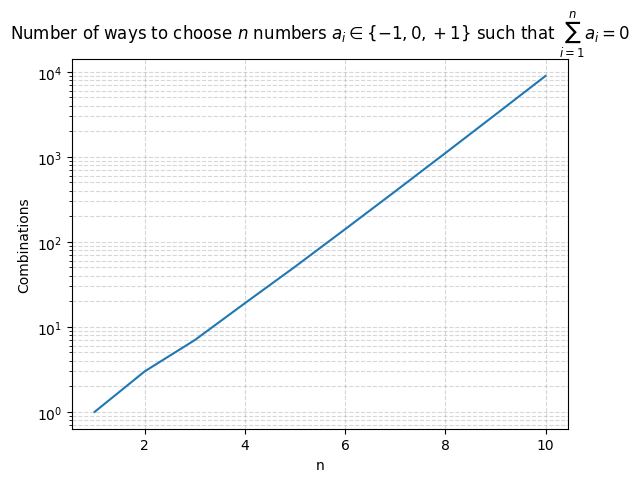

In [5]:
def plot_number(ns, n_combinations):
    plt.plot(ns, n_combinations)
    plt.yscale("log")
    plt.xlabel("n")
    plt.ylabel("Combinations")
    plt.title(r'Number of ways to choose $n$ numbers $a_i \in \{-1,0,+1\}$ such that $\sum_{i=1}^n a_i = 0$')
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    return n_combinations

n_combinations = plot_number(ns, n_combinations)

slope: 1.0060094939815345
intercept: -1.0326353176938077


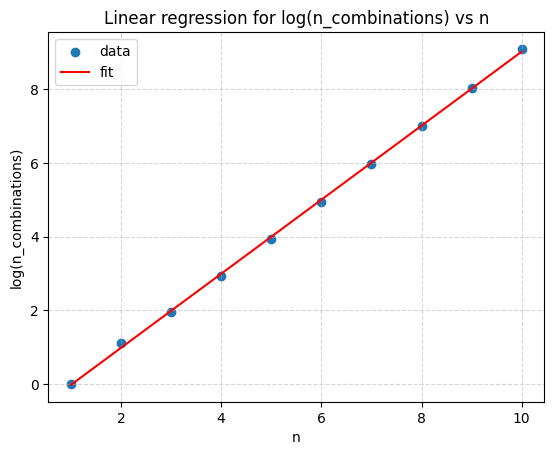

In [6]:
def plot_fit(ns, n_combinations):

    log_n_combinations = np.log(n_combinations)
    slope, intercept = np.polyfit(ns, log_n_combinations, 1)

    print("slope:", slope)
    print("intercept:", intercept)

    plt.scatter(ns, log_n_combinations, label="data")
    plt.plot(ns, slope * np.array(ns) + intercept, color="red", label="fit")
    plt.xlabel("n")
    plt.ylabel("log(n_combinations)")
    plt.title("Linear regression for log(n_combinations) vs n")
    plt.legend()
    plt.grid(True, which="both", linestyle="--", alpha=0.5)

plot_fit(ns, n_combinations)

In [8]:
components = 10
connections = components * (components - 1)//2
valid_combinations = constrained_sum_combinations(connections)
total_combinations = 3 ** connections
valid_combination_proportion =  valid_combinations / total_combinations
effective_dimensions = log(valid_combinations, 3)

print(f"There are {connections} between {components} components.")
print(f"If each connection can be weak, strong or normal, there are {total_combinations} ways to do that.")
print(f"If we add the constraint that each strong connection must be balanced by another weak connection, there are {valid_combinations} ways to do that.")
print(f"That means that only {valid_combination_proportion*100:0.0f}% combinations are valid.")
print(f"That corresponds to {effective_dimensions:0.1f} effective dimensions.")



There are 45 between 10 components.
If each connection can be weak, strong or normal, there are 2954312706550833698643 ways to do that.
If we add the constraint that each strong connection must be balanced by another weak connection, there are 214285636273290835239 ways to do that.
That means that only 7% combinations are valid.
That corresponds to 42.6 effective dimensions.


### Random Connection States

The animation below places ten objects around a circle and shows the 45 pairwise connections between them. Each frame samples a balanced ternary configuration: weak (`-1`), normal (`0`), or strong (`+1`). Line widths and colors make the three connection states easy to distinguish.

In [11]:
def sample_connection_states(edge_count: int, random_generator: np.random.Generator, balanced: bool = True) -> np.ndarray:
    """Return a random ternary state for every connection."""
    while True:
        states = random_generator.integers(-1, 2, size=edge_count)
        if not balanced or states.sum() == 0:
            return states


def random_connection_animation(
    number_of_objects: int = 10,
    frame_count: int = 80,
    interval_ms: int = 140,
    seed: int = 2026,
) -> HTML:
    """Create an animation of random connection states between objects."""
    random_generator = np.random.default_rng(seed)
    angles = np.linspace(0, 2 * np.pi, number_of_objects, endpoint=False) + np.pi / 2
    positions = np.column_stack((np.cos(angles), np.sin(angles)))
    edge_pairs = [
        (first, second)
        for first in range(number_of_objects)
        for second in range(first + 1, number_of_objects)
    ]
    segments = [
        [positions[first].tolist(), positions[second].tolist()]
        for first, second in edge_pairs
    ]

    colors = {-1: "#6FA8DC", 0: "#9AA3B2", 1: "#E07A5F"}
    widths = {-1: 1.0, 0: 2.0, 1: 3.0}
    initial_states = sample_connection_states(len(edge_pairs), random_generator)

    figure, axis = plt.subplots(figsize=(7, 7))
    line_collection = LineCollection(
        segments,
        linewidths=[widths[state] for state in initial_states],
        colors=[colors[state] for state in initial_states],
        alpha=0.78,
        capstyle="round",
    )
    axis.add_collection(line_collection)
    axis.scatter(
        positions[:, 0],
        positions[:, 1],
        s=420,
        color="#F4F1DE",
        edgecolor="#264653",
        linewidth=2,
        zorder=2,
    )
    for object_number, (x_position, y_position) in enumerate(positions, start=1):
        axis.text(
            x_position,
            y_position,
            str(object_number),
            ha="center",
            va="center",
            color="#264653",
            fontsize=10,
            fontweight="bold",
            zorder=3,
        )

    axis.set_xlim(-1.25, 1.25)
    axis.set_ylim(-1.25, 1.25)
    axis.set_aspect("equal")
    axis.axis("off")
    axis.set_title("Random balanced connection states", color="#264653", pad=18)
    legend_handles = [
        Line2D([0], [0], color=colors[-1], linewidth=widths[-1], label="Weak"),
        Line2D([0], [0], color=colors[0], linewidth=widths[0], label="Normal"),
        Line2D([0], [0], color=colors[1], linewidth=widths[1], label="Strong"),
    ]
    axis.legend(handles=legend_handles, loc="lower center", ncol=3, frameon=False)

    def update(_frame_number: int) -> tuple[LineCollection]:
        """Update all connection styles for one animation frame."""
        states = sample_connection_states(len(edge_pairs), random_generator)
        line_collection.set_linewidth([widths[state] for state in states])
        line_collection.set_color([colors[state] for state in states])
        return (line_collection,)

    animation = FuncAnimation(
        figure,
        update,
        frames=frame_count,
        interval=interval_ms,
        blit=True,
        repeat=True,
        cache_frame_data=False,
    )
    plt.close(figure)
    return HTML(animation.to_jshtml(fps=7))


display(random_connection_animation())